In [1]:
import pandas as pd
from optimize import grid_search, DEFAULT_SEARCH_SPACE
from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEARCH_SPACE = {
    "minimum_profit": [1.1, 1.5, 2.0],
    # "cooldown_long": [30, 60, 90],
    # "cooldown_short": [7, 14, 30],
}

In [3]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True).dropna(axis=1)
df_prices

,BTC,ETH,XRP,USDT,BCH,LTC,EOS,BNB,BSV,XLM,...,MKR,ONT,DOGE,VET,BAT,OMG,SNX,ZRX,ICX,QTUM
Date,,,,,,,,,,,,,,,,,,,,,
2020-02-13,10214.379883,268.099243,0.326706,0.998579,474.317993,80.403427,5.341575,25.440100,359.041138,0.082655,...,625.763184,1.021036,0.003026,0.008026,0.295389,1.280141,0.932967,0.320865,0.394342,2.842507
2020-02-14,10312.116211,284.217499,0.334822,1.000114,491.160645,82.990349,5.361947,26.296959,360.390015,0.085796,...,638.993713,1.071109,0.003130,0.008323,0.311020,1.370907,0.992797,0.345264,0.400229,3.015611
2020-02-15,9889.424805,264.728577,0.306236,0.999128,437.664948,76.513245,4.743118,24.149651,310.077820,0.079246,...,607.280212,0.957589,0.002920,0.007440,0.280342,1.289413,0.949770,0.317226,0.360399,2.677241
2020-02-16,9934.433594,259.894714,0.295034,0.999272,415.940643,75.152588,4.412250,23.466389,285.867523,0.075079,...,634.711975,0.909603,0.002774,0.007133,0.264260,1.190897,0.945258,0.299002,0.348740,2.511193
2020-02-17,9690.142578,266.363434,0.286572,0.998474,409.344574,73.251305,4.346360,23.551378,309.441620,0.071851,...,614.943604,0.878514,0.002712,0.006756,0.266563,1.169630,1.011205,0.291352,0.344687,2.499368
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-31,68233.312500,2104.708252,1.340259,0.999024,466.334564,53.917908,0.075516,617.049194,13.852106,0.167265,...,1740.242554,0.083272,0.092208,0.006763,0.096228,0.054769,0.287147,0.103136,0.034007,0.887649
2026-04-01,68078.554688,2138.737061,1.347766,0.999800,454.311554,53.805855,0.078632,610.622986,14.003111,0.169253,...,1785.234497,0.112436,0.092191,0.006885,0.099325,0.055448,0.281543,0.104537,0.035458,0.930321
2026-04-02,66888.570312,2056.852539,1.318691,0.999892,444.056213,52.260174,0.076542,583.136841,14.614312,0.163015,...,1750.205811,0.108114,0.090374,0.006740,0.094341,0.053399,0.278585,0.102121,0.035270,0.879604


In [4]:
results, best = grid_search(
    prices=df_prices, 
    param_grid=SEARCH_SPACE, 
    metric="RoAC",
    n_boot=20,
    sample_size=10,
    sequence_length=365 * 4,
    )

100%|██████████| 3/3 [00:29<00:00,  9.79s/it]


In [5]:
results

,minimum_profit,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC
0,1.5,1928.465,1199.925,1549.185,1362.825,2749.600,40.125,1534.576100,5.630,-45.350,-1070.200,74.725783,8.080
1,2.0,1962.505,901.390,1611.805,1594.875,2513.500,37.345,956.746237,4.945,-51.740,-1394.885,91.730707,5.315
2,1.1,1922.685,1209.715,1490.470,1179.340,2700.655,37.695,1314.237518,6.465,-46.155,-1031.935,78.569195,3.940


In [6]:
best

{'minimum_profit': np.float64(1.5)}

In [7]:
bt = BacktestDCA("BTC", df_prices["BTC"], strategy=best)
history, metrics = bt.run()

23:29:31 - cmdstanpy - INFO - Chain [1] start processing
23:29:31 - cmdstanpy - INFO - Chain [1] done processing


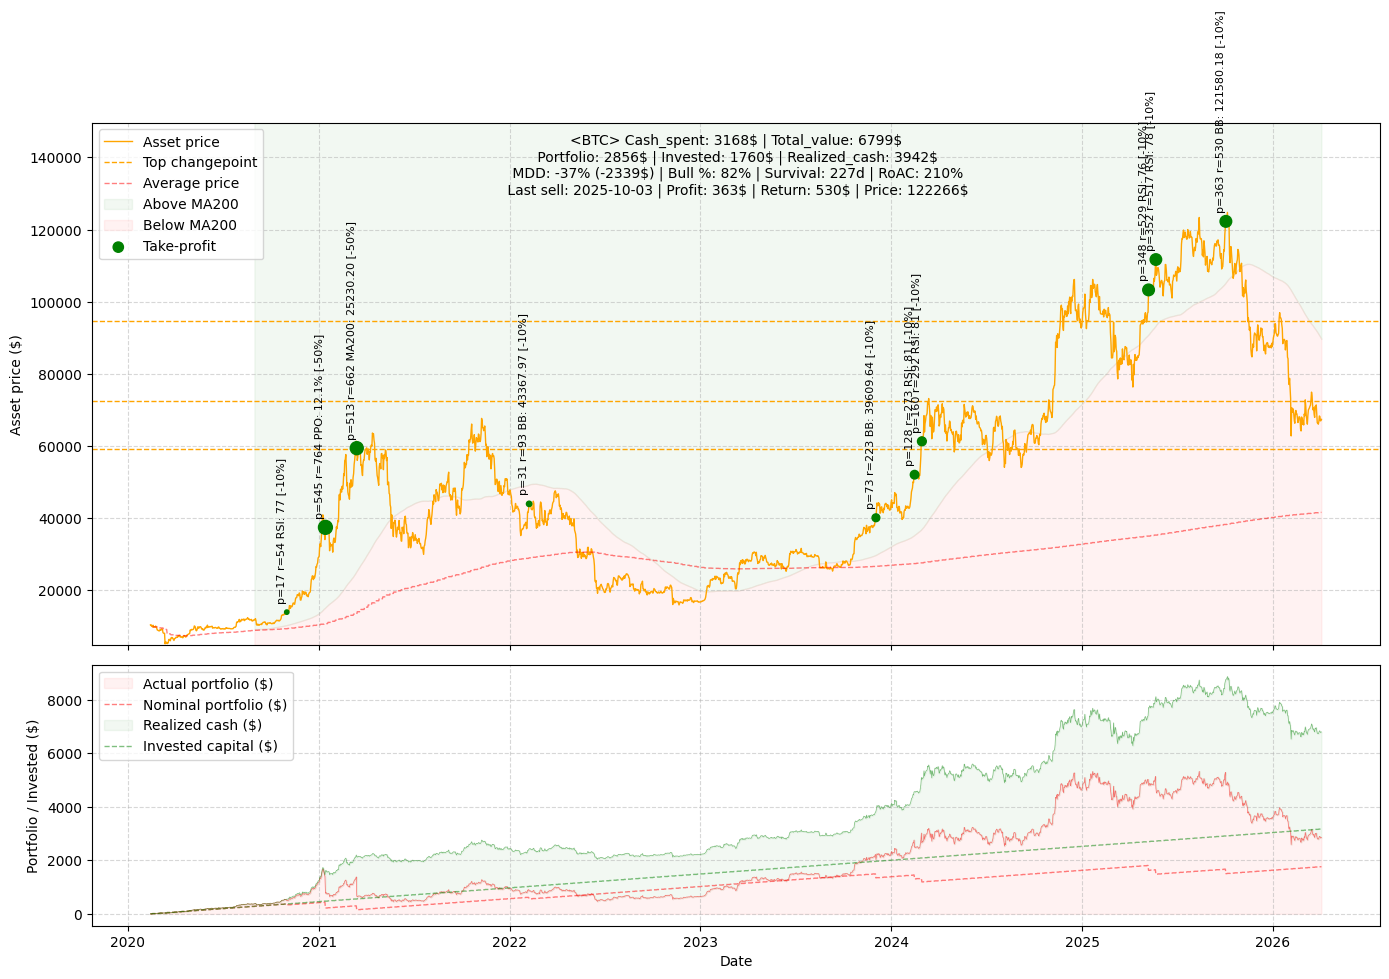

In [8]:
ploter(metrics=metrics, history=history)